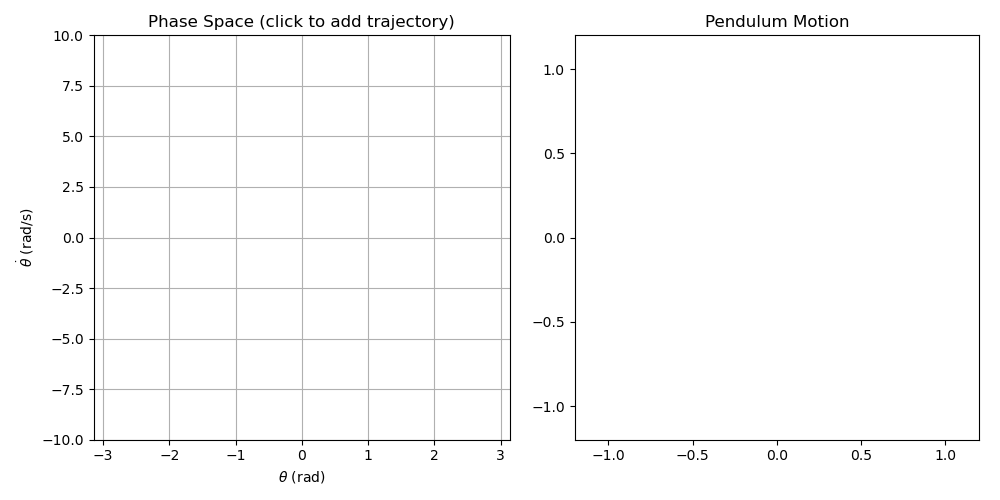

In [1]:
# Interactive Pendulum Phase Space + Real-Time Animation
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from matplotlib.animation import FuncAnimation
from ipywidgets import Button, VBox, HBox, Output
%matplotlib widget

# --- Physical parameters ---
g, L = 9.81, 1.0
t_max, dt = 30, 0.01

# --- Pendulum ODE ---
def pendulum(t, y):
    θ, ω = y
    return [ω, -(g/L)*np.sin(θ)]

def integrate_trajectory(θ0, ω0):
    t_eval = np.arange(0, t_max, dt)
    sol = solve_ivp(pendulum, [0, t_max], [θ0, ω0], t_eval=t_eval)
    return sol.t, sol.y[0], sol.y[1]

# --- Set up figure ---
fig, (ax_phase, ax_pend) = plt.subplots(1, 2, figsize=(10, 5))

ax_phase.set_title("Phase Space (click to add trajectory)")
ax_phase.set_xlabel(r"$\theta$ (rad)")
ax_phase.set_ylabel(r"$\dot{\theta}$ (rad/s)")
ax_phase.grid(True)
ax_phase.set_xlim(-np.pi, np.pi)
ax_phase.set_ylim(-10, 10)

ax_pend.set_xlim(-1.2*L, 1.2*L)
ax_pend.set_ylim(-1.2*L, 1.2*L)
ax_pend.set_aspect('equal')
ax_pend.set_title("Pendulum Motion")

(line_pend,) = ax_pend.plot([], [], 'o-', lw=2)
(line_trace,) = ax_phase.plot([], [], lw=1.5)

trajectories = []
animations = []
out = Output()

# --- Pendulum animation ---
def animate_pendulum(t_vals, θ_vals, ω_vals):
    """Animate both the pendulum and the trace on the phase plot."""

    def update(frame):
        θ = θ_vals[frame]
        ω = ω_vals[frame]
        x = L * np.sin(θ)
        y = -L * np.cos(θ)
        line_pend.set_data([0, x], [0, y])
        line_trace.set_data(θ_vals[:frame], ω_vals[:frame])
        return line_pend, line_trace

    ani = FuncAnimation(fig, update, frames=len(t_vals),
                        interval=dt*1000, blit=True, repeat=False)
    animations.append(ani)  # prevent garbage collection
    return ani

# --- Click handler ---
def on_click(event):
    if event.inaxes != ax_phase:
        return
    θ0, ω0 = event.xdata, event.ydata
    t_vals, θ_vals, ω_vals = integrate_trajectory(θ0, ω0)
    θ_wrapped = (θ_vals + np.pi) % (2*np.pi) - np.pi
    line, = ax_phase.plot(θ_wrapped, ω_vals, '.')
    trajectories.append(line)
    fig.canvas.draw_idle()
    
    T = estimate_period(t_vals, θ_vals)
    
    T0 = 2*np.pi/np.sqrt(g/L)
    A = estimate_amplitude(θ_vals)
    with out:
        if T:
            print(f"Trajectory added: Max amplitude θmax={A:.2f}, Period/Period_SHO ≈ {T/T0:.3f}")
        else:
            print(f"Trajectory added: Max amplitude θmax={A:.2f},  Period undetermined (no full oscillation)")
    
    animate_pendulum(t_vals, θ_vals, ω_vals)

# --- Clear button ---
clear_btn = Button(description="Clear Trajectories", button_style='danger')

def clear_plot(b):
    for line in trajectories:
        line.remove()
    trajectories.clear()
    ax_phase.figure.canvas.draw_idle()
    with out:
        print("Cleared all trajectories.")

# --- Estimate maximum amplitude ---
def estimate_amplitude(θ):
    return np.max(np.abs(θ))

# --- Estimate oscillation period ---
def estimate_period(t, θ):
    θ = np.unwrap(θ)  # remove jumps around π
    sign_changes = np.where(np.diff(np.sign(θ)))[0]
    if len(sign_changes) < 3:
        return None  # not enough crossings for a period
    # Time between every other zero crossing (full oscillation)
    crossings_t = t[sign_changes]
    full_periods = np.diff(crossings_t[::2])
    if len(full_periods) == 0:
        return None
    return np.mean(full_periods)

clear_btn.on_click(clear_plot)
fig.canvas.mpl_connect('button_press_event', on_click)

ui = VBox([HBox([clear_btn]), out])
display(ui)
plt.tight_layout()
plt.show()


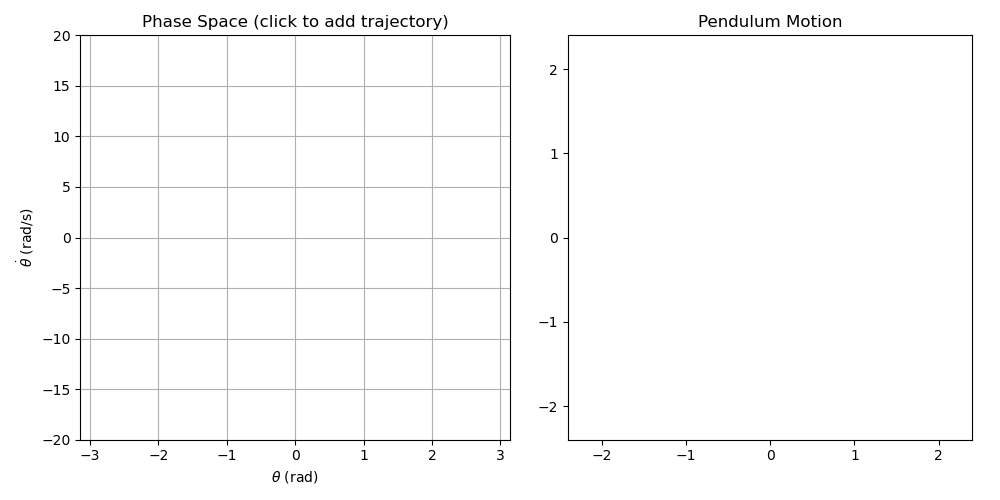

In [1]:
# Interactive Pendulum Phase Space + Real-Time Animation
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from matplotlib.animation import FuncAnimation
from ipywidgets import Button, VBox, HBox, Output
%matplotlib widget

# --- Physical parameters ---
g, L, a, Omega = 9.81, 1.0, 1, 1
t_max, dt = 10, 0.001

# --- Pendulum ODE ---
def pendulum(t, y):
    θ, ω = y
    w0 = np.sqrt(g/L)
    return [ω, -(w0**2+a*Omega**2/L*np.cos(Omega*t))*np.sin(θ)]

def integrate_trajectory(θ0, ω0):
    t_eval = np.arange(0, t_max, dt)
    sol = solve_ivp(pendulum, [0, t_max], [θ0, ω0], t_eval=t_eval)
    return sol.t, sol.y[0], sol.y[1]

# --- Set up figure ---
fig, (ax_phase, ax_pend) = plt.subplots(1, 2, figsize=(10, 5))

ax_phase.set_title("Phase Space (click to add trajectory)")
ax_phase.set_xlabel(r"$\theta$ (rad)")
ax_phase.set_ylabel(r"$\dot{\theta}$ (rad/s)")
ax_phase.grid(True)
ax_phase.set_xlim(-np.pi, np.pi)
ax_phase.set_ylim(-20, 20)

ax_pend.set_xlim(-1.2*(a+L), 1.2*(a+L))
ax_pend.set_ylim(-1.2*(a+L), 1.2*(a+L))
ax_pend.set_aspect('equal')
ax_pend.set_title("Pendulum Motion")

try:
    for line in trajectories:
        line.remove()
except NameError:
    pass

trajectories = []
animations = []

(line_pend,) = ax_pend.plot([], [], 'o-', lw=2)
(line_trace,) = ax_phase.plot([], [], lw=1.5)

try:
    out.clear_output()
except:
    pass
out = Output()

# --- Pendulum animation ---
def animate_pendulum(t_vals, θ_vals, ω_vals):
    """Animate both the pendulum and the trace on the phase plot."""

    def update(frame):
        θ = θ_vals[frame]
        ω = ω_vals[frame]
        t = t_vals[frame]
        x = L * np.sin(θ)
        y = -L * np.cos(θ)
        line_pend.set_data([0, x], [a*np.cos(Omega*t), a*np.cos(Omega*t)+y])
        line_trace.set_data(θ_vals[:frame], ω_vals[:frame])
        return line_pend, line_trace

    ani = FuncAnimation(fig, update, frames=len(t_vals),
                        interval=dt*1000, blit=True, repeat=False)
    animations.append(ani)  # prevent garbage collection
    return ani

# --- Click handler ---
def on_click(event):
    if event.inaxes != ax_phase:
        return
    θ0, ω0 = event.xdata, event.ydata
    t_vals, θ_vals, ω_vals = integrate_trajectory(θ0, ω0)
    θ_wrapped = (θ_vals + np.pi) % (2*np.pi) - np.pi
    line, = ax_phase.plot(θ_wrapped, ω_vals, '.')
    trajectories.append(line)
    fig.canvas.draw_idle()
    
    T = estimate_period(t_vals, θ_vals) 
    
    T0 = 2*np.pi/np.sqrt(g/L)
    A = estimate_amplitude(θ_vals)
    animate_pendulum(t_vals, θ_vals, ω_vals)

# --- Clear button ---
clear_btn = Button(description="Clear Trajectories", button_style='danger')

def clear_plot(b):
    for line in trajectories:
        line.remove()
    trajectories.clear()
    ax_phase.figure.canvas.draw_idle()
    with out:
        print("Cleared all trajectories.")

# --- Estimate maximum amplitude ---
def estimate_amplitude(θ):
    return np.max(np.abs(θ))

# --- Estimate oscillation period ---
def estimate_period(t, θ):
    θ = np.unwrap(θ)  # remove jumps around π
    sign_changes = np.where(np.diff(np.sign(θ)))[0]
    if len(sign_changes) < 3:
        return None  # not enough crossings for a period
    # Time between every other zero crossing (full oscillation)
    crossings_t = t[sign_changes]
    full_periods = np.diff(crossings_t[::2])
    if len(full_periods) == 0:
        return None
    return np.mean(full_periods)

clear_btn.on_click(clear_plot)
fig.canvas.mpl_connect('button_press_event', on_click)

ui = VBox([HBox([clear_btn]), out])
display(ui)
plt.tight_layout()
plt.show()


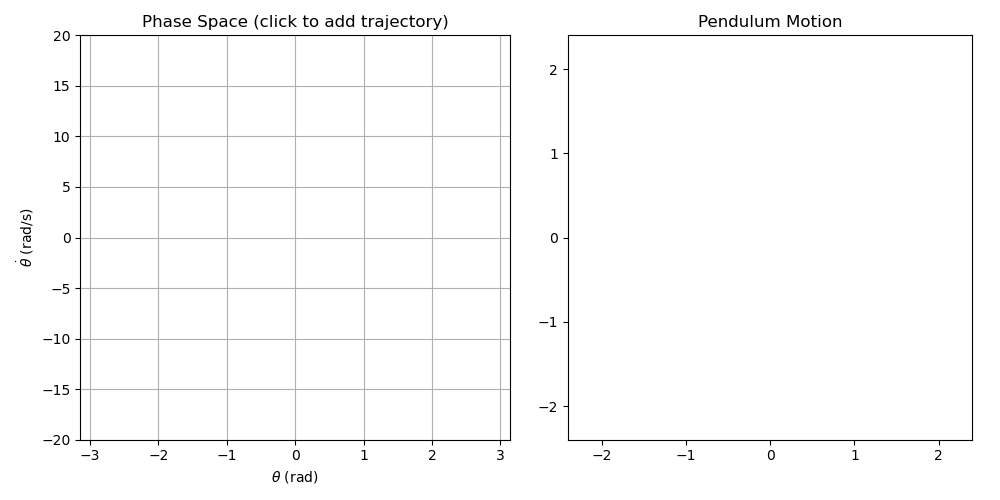

In [1]:
# Interactive Pendulum Phase Space + Real-Time Animation
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from matplotlib.animation import FuncAnimation
from ipywidgets import Button, VBox, HBox, Output
%matplotlib widget

# --- Physical parameters ---
g, L, a, Omega = 9.81, 1.0, 1, 1
t_max, dt = 10, 0.001

# --- Pendulum ODE ---
def pendulum(t, y):
    θ, ω = y
    w0 = np.sqrt(g/L)
    return [ω, -(w0**2+a*Omega**2/L*np.cos(Omega*t))*np.sin(θ)]

def angular_accel(theta, t):
    """Angular acceleration for a vertically driven pendulum."""
    return - (g / L + (a * Omega**2 / L) * np.cos(Omega * t)) * np.sin(theta)

# --- Symplectic Leapfrog Integrator ---
def integrate_leapfrog(theta0, omega0, tmax=tmax, dt=dt):
    n_steps = int(tmax / dt)
    t_vals = np.linspace(0, tmax, n_steps)
    theta_vals = np.zeros(n_steps)
    omega_vals = np.zeros(n_steps)

    # Initial conditions
    theta = theta0
    omega = omega0

    # First half-step for velocity
    omega += 0.5 * dt * angular_accel(theta, 0.0)

    for i in range(n_steps):
        t = i * dt
        theta += dt * omega                # full step position
        omega += dt * angular_accel(theta, t + dt/2.0)  # full step velocity

        # Wrap angle to [-pi, pi]
        if theta > np.pi:
            theta -= 2 * np.pi
        elif theta < -np.pi:
            theta += 2 * np.pi

        theta_vals[i] = theta
        omega_vals[i] = omega

    return t_vals, theta_vals, omega_vals
    
def integrate_trajectory(θ0, ω0):
    t_eval = np.arange(0, t_max, dt)
    sol = solve_ivp(pendulum, [0, t_max], [θ0, ω0], t_eval=t_eval)
    return sol.t, sol.y[0], sol.y[1]

def integrate_section(θ0, ω0):
    Npts = 100
    t_eval = np.arange(Npts)*2*np.pi/Omega
    sol = solve_ivp(pendulum, [0, t_eval[-1]], [θ0, ω0], t_eval=t_eval)
    return sol.t, sol.y[0], sol.y[1]

# --- Set up figure ---
fig, (ax_phase, ax_pend) = plt.subplots(1, 2, figsize=(10, 5))

ax_phase.set_title("Phase Space (click to add trajectory)")
ax_phase.set_xlabel(r"$\theta$ (rad)")
ax_phase.set_ylabel(r"$\dot{\theta}$ (rad/s)")
ax_phase.grid(True)
ax_phase.set_xlim(-np.pi, np.pi)
ax_phase.set_ylim(-20, 20)

ax_pend.set_xlim(-1.2*(a+L), 1.2*(a+L))
ax_pend.set_ylim(-1.2*(a+L), 1.2*(a+L))
ax_pend.set_aspect('equal')
ax_pend.set_title("Pendulum Motion")

try:
    for line in trajectories:
        line.remove()
except NameError:
    pass

trajectories = []
animations = []

(line_pend,) = ax_pend.plot([], [], 'o-', lw=2)
(line_trace,) = ax_phase.plot([], [], lw=1.5)

try:
    out.clear_output()
except:
    pass
out = Output()

current_animation = [None]  # store in list for mutable reference

def stop_current_animation():
    """Stop any running animation cleanly."""
    ani = current_animation[0]
    if ani is not None:
        ani.event_source.stop()
        current_animation[0] = None

# --- Pendulum animation ---
def animate_pendulum(t_vals, θ_vals, ω_vals):
    """Animate both the pendulum and the trace on the phase plot."""

    
    def update(frame):
        θ = θ_vals[frame]
        ω = ω_vals[frame]
        t = t_vals[frame]
        x = L * np.sin(θ)
        y = -L * np.cos(θ)
        line_pend.set_data([0, x], [a*np.cos(Omega*t), a*np.cos(Omega*t)+y])
        #line_trace.set_data(θ_vals[:frame], ω_vals[:frame])
        return line_pend, line_trace

    stop_current_animation()  # stop prior animation
    ani = FuncAnimation(fig, update, frames=len(t_vals),
                        interval=dt*1000, blit=True, repeat=False)
    animations.append(ani)  # prevent garbage collection
    return ani

# --- Click handler ---
def on_click(event):
    if event.inaxes != ax_phase:
        return

    # stop any running animation immediately
    stop_current_animation()
    
    θ0, ω0 = event.xdata, event.ydata
    t_vals, θ_vals, ω_vals = integrate_trajectory(θ0, ω0)
    θ_wrapped = (θ_vals + np.pi) % (2*np.pi) - np.pi
    sec_t_vals, sec_θ_vals, sec_ω_vals = integrate_section(θ0, ω0)
    sec_θ_wrapped = (sec_θ_vals + np.pi) % (2*np.pi) - np.pi
    line, = ax_phase.plot(sec_θ_wrapped, sec_ω_vals, '.')
    trajectories.append(line)
    fig.canvas.draw_idle()
    
    animate_pendulum(t_vals, θ_vals, ω_vals)

# --- Clear button ---
clear_btn = Button(description="Clear Trajectories", button_style='danger')

def clear_plot(b):
    for line in trajectories:
        line.remove()
    trajectories.clear()
    ax_phase.figure.canvas.draw_idle()
    with out:
        print("Cleared all trajectories.")

# --- Estimate maximum amplitude ---
def estimate_amplitude(θ):
    return np.max(np.abs(θ))

# --- Estimate oscillation period ---
def estimate_period(t, θ):
    θ = np.unwrap(θ)  # remove jumps around π
    sign_changes = np.where(np.diff(np.sign(θ)))[0]
    if len(sign_changes) < 3:
        return None  # not enough crossings for a period
    # Time between every other zero crossing (full oscillation)
    crossings_t = t[sign_changes]
    full_periods = np.diff(crossings_t[::2])
    if len(full_periods) == 0:
        return None
    return np.mean(full_periods)

clear_btn.on_click(clear_plot)
fig.canvas.mpl_connect('button_press_event', on_click)

ui = VBox([HBox([clear_btn]), out])
display(ui)
plt.tight_layout()
plt.show()


In [3]:
θ0, ω0 = 1.5, 0
t_vals, θ_vals, ω_vals = integrate_trajectory(θ0, ω0)
θ_wrapped = (θ_vals + np.pi) % (2*np.pi) - np.pi
sec_t_vals, sec_θ_vals, sec_ω_vals = integrate_section(θ0, ω0)
sec_θ_wrapped = (sec_θ_vals + np.pi) % (2*np.pi) - np.pi

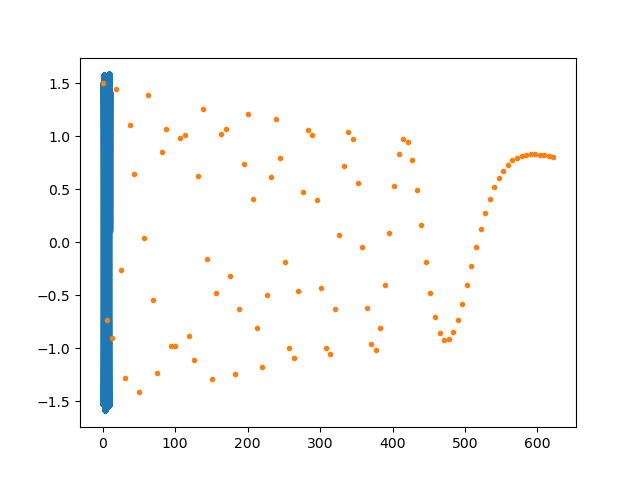

In [5]:
fig, ax = plt.subplots()
ax.plot(t_vals, θ_vals, '.')
ax.plot(sec_t_vals, sec_θ_vals, '.')

In [28]:
np.sqrt(g/L)/Omega, a*Omega**2/g

(np.float64(1.5660459763365826), 0.4077471967380224)

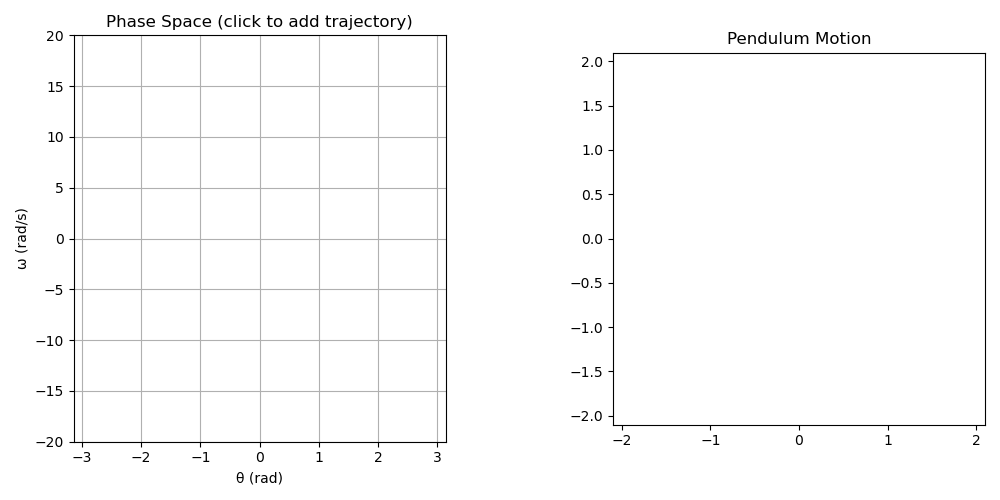

In [4]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from ipywidgets import Button, VBox, HBox, Output
from IPython.display import display

# ======================
# Parameters
# ======================
g = 9.81
L = 1.0
a = 1        # pivot amplitude (m)
Omega = 2    # drive freq (rad/s)
dt = 0.01
tmax = 20.0

# perturbation for divergence
delta_theta = 1e-4
delta_omega = 0.0

# output parameters
Nout = 1000
Nsec = 100

# ======================
# Dynamics (correct driven eqn)
# ======================
def angular_accel(theta, t):
    # correct sign: g - a * Omega^2 * cos(...) appears in numerator
    return - ((g - a * Omega**2 * np.cos(Omega * t)) / L) * np.sin(theta)

# ======================
# Symplectic leapfrog integrator
# ======================
def integrate_leapfrog2(theta0, omega0, tmax=tmax, dt=dt):
    t_vals = np.arange(0.0, tmax + 1e-12, dt)
    n_steps = len(t_vals)
    theta_vals = np.zeros(n_steps)
    omega_vals = np.zeros(n_steps)

    theta = float(theta0)
    # half-step velocity initialization
    omega = float(omega0) + 0.5 * dt * angular_accel(theta, 0.0)

    for i in range(n_steps):
        t = t_vals[i]
        theta = theta + dt * omega               # position update
        # velocity update using mid-point time t + dt/2
        omega = omega + dt * angular_accel(theta, t + 0.5 * dt)

        # wrap angle into [-pi, pi] for nicer phase plots
        if theta > np.pi:
            theta -= 2.0 * np.pi
        elif theta < -np.pi:
            theta += 2.0 * np.pi

        theta_vals[i] = theta
        omega_vals[i] = omega

    return t_vals, theta_vals, omega_vals

def integrate_leapfrog(theta0, omega0, t_out, dt=0.001):
    """
    Symplectic leapfrog integrator for driven pendulum.

    Parameters
    ----------
    theta0, omega0 : float
        Initial conditions.
    t_out : array_like
        Array of times at which to return results (need not be uniform).
    dt : float
        Internal integration timestep.

    Returns
    -------
    t_out : ndarray
        Output times (same as input, sorted).
    theta_out, omega_out : ndarray
        Arrays of theta and omega at each output time.
    """
    t_out = np.array(t_out)
    t_out.sort()
    t_end = t_out[-1]

    # Preallocate output arrays
    theta_out = np.zeros_like(t_out)
    omega_out = np.zeros_like(t_out)

    # Initial conditions
    theta = float(theta0)
    omega = float(omega0) + 0.5 * dt * angular_accel(theta, 0.0)  # half-step

    # Integration loop
    t = 0.0
    next_index = 0
    n_out = len(t_out)

    for step in range(int(t_end / dt) + 2):
        # Output if we've reached or passed a requested output time
        while next_index < n_out and t >= t_out[next_index]:
            theta_out[next_index] = theta
            omega_out[next_index] = omega - 0.5 * dt * angular_accel(theta, t)  # back to integer step
            next_index += 1
            if next_index == n_out:
                break
        if next_index == n_out:
            break

        # Standard leapfrog update
        theta += dt * omega
        omega += dt * angular_accel(theta, t + 0.5 * dt)
        t += dt

        # wrap angle to [-pi, pi]
        if theta > np.pi:
            theta -= 2 * np.pi
        elif theta < -np.pi:
            theta += 2 * np.pi

    return t_out, theta_out, omega_out
    
# ======================
# Figure / axes setup
# ======================
fig, (ax_phase, ax_pend) = plt.subplots(1, 2, figsize=(10, 5))

# pendulum picture
ax_pend.set_title("Pendulum Motion")
ax_pend.set_xlim(-L - a - 0.1, L + a + 0.1)
ax_pend.set_ylim(-L - a - 0.1, L + a + 0.1)
ax_pend.set_aspect('equal')

# phase space
ax_phase.set_title("Phase Space (click to add trajectory)")
ax_phase.set_xlabel("θ (rad)")
ax_phase.set_ylabel("ω (rad/s)")
ax_phase.set_xlim(-np.pi, np.pi)
ax_phase.set_ylim(-20, 20)
ax_phase.grid(True)

plt.tight_layout()
plt.subplots_adjust(wspace=0.45)

# ======================
# State containers
# ======================
trajectories = []   # static phase-space traces
animations = []     # keep references to animations if needed

# output widget
out = Output()
display(VBox([out]))

# current running animation and its artists (we'll stop/remove before starting new)
current_animation = {"ani": None, "pend_line": None, "trace_line": None}

# ======================
# Utility: stop & remove current animation and its artists
# ======================
def stop_current_animation():
    ani = current_animation.get("ani")
    if ani is not None:
        # stop event source
        try:
            ani.event_source.stop()
        except Exception:
            pass
    # remove artists from axes so they won't be visible/updated
    for key in ("pend_line", "trace_line"):
        art = current_animation.get(key)
        if art is not None:
            try:
                art.remove()
            except Exception:
                pass
    # clear stored refs
    current_animation["ani"] = None
    current_animation["pend_line"] = None
    current_animation["trace_line"] = None
    # redraw canvas
    try:
        fig.canvas.draw_idle()
    except Exception:
        pass

# ======================
# animate_pendulum (creates a new FuncAnimation but uses its own artists)
# ======================
def animate_pendulum(t_vals, theta_vals, omega_vals, color='C1'):
    # stop & remove previous animation + artists first
    stop_current_animation()

    # create local artists for this animation (so multiple animations don't share artists)
    pend_line, = ax_pend.plot([], [], 'o-', lw=2, color=color)
    trace_line, = ax_phase.plot([], [], lw=1.5, color=color)

    # store them in current_animation so we can remove later
    current_animation["pend_line"] = pend_line
    current_animation["trace_line"] = trace_line

    # update function for this animation
    def update(frame_index):
        i = int(frame_index)
        if i < 0 or i >= len(t_vals):
            return pend_line, trace_line

        t_now = float(t_vals[i])
        theta = float(theta_vals[i])
        omega = float(omega_vals[i])

        y_pivot = a * np.cos(Omega * t_now)
        x = L * np.sin(theta)
        y = y_pivot - L * np.cos(theta)

        pend_line.set_data([0.0, x], [y_pivot, y])
        trace_line.set_data(theta_vals[:i], omega_vals[:i])
        return pend_line, trace_line

    # create animation for exactly len(t_vals) frames
    ani = FuncAnimation(fig, update, frames=range(len(t_vals)),
                        interval=dt*1000, blit=True, repeat=False)

    # keep reference & return
    current_animation["ani"] = ani
    animations.append(ani)
    return ani

# ======================
# Click handler
# ======================
def on_click(event):
    if event.inaxes != ax_phase:
        return

    theta0, omega0 = float(event.xdata), float(event.ydata)

    # integrate using leapfrog
    t_vals, theta_vals, omega_vals = integrate_leapfrog(theta0, omega0, t_out, dt)
    # static phase trace (wrapped for neatness)
    #theta_wrapped = (theta_vals + np.pi) % (2.0 * np.pi) - np.pi
    line = ax_phase.plot(theta_vals, omega_vals, alpha=0.)[0]
    trajectories.append(line)
    fig.canvas.draw_idle()

    

    # start the animation for this trajectory (uses leapfrog arrays)
    animate_pendulum(t_vals, theta_vals, omega_vals, color=None)

# connect click
cid = fig.canvas.mpl_connect('button_press_event', on_click)

# ======================
# Clear button (stop + remove traces & divergence)
# ======================
clear_btn = Button(description="Clear", button_style="danger")
def clear_all(b=None):
    stop_current_animation()
    # remove static trajectories and div lines
    for ln in trajectories:
        try:
            ln.remove()
        except Exception:
            pass
    trajectories.clear()
    
    fig.canvas.draw_idle()
    with out:
        out.clear_output()
        print("Cleared trajectories and divergence plots.")
clear_btn.on_click(clear_all)

# display clear button
display(HBox([clear_btn]))

# ======================
# Done — the animations will be created by animate_pendulum (leapfrog data)
# ======================
plt.show()


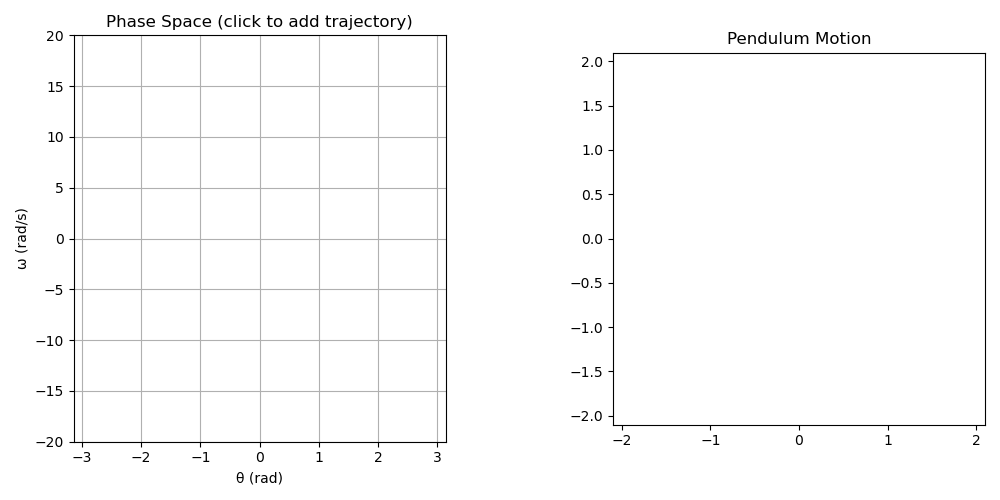

In [5]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from ipywidgets import Button, VBox, HBox, Output
from IPython.display import display

# Parameters
g = 9.81
L = 1.0
a = 1        # pivot amplitude (m)
Omega = 2    # drive freq (rad/s)

# output parameters
dt = 0.01 # integrator timestep
tmax = 20.0
Nout = 1000
Nsec = 100
t_out = np.linspace(0, tmax, Nout)
t_sec = np.arange(Nsec)*(2*np.pi/Omega)

# ======================
# Dynamics (correct driven eqn)
# ======================
def angular_accel(theta, t):
    # correct sign: g - a * Omega^2 * cos(...) appears in numerator
    return - ((g - a * Omega**2 * np.cos(Omega * t)) / L) * np.sin(theta)

# ======================
# Symplectic leapfrog integrator
# ======================
def integrate_leapfrog(theta0, omega0, t_out, dt=0.001):
    """
    Symplectic leapfrog integrator for driven pendulum.

    Parameters
    ----------
    theta0, omega0 : float
        Initial conditions.
    t_out : array_like
        Array of times at which to return results (need not be uniform).
    dt : float
        Internal integration timestep.

    Returns
    -------
    t_out : ndarray
        Output times (same as input, sorted).
    theta_out, omega_out : ndarray
        Arrays of theta and omega at each output time.
    """
    t_out = np.array(t_out)
    t_out.sort()
    t_end = t_out[-1]

    # Preallocate output arrays
    theta_out = np.zeros_like(t_out)
    omega_out = np.zeros_like(t_out)

    # Initial conditions
    theta = float(theta0)
    omega = float(omega0) + 0.5 * dt * angular_accel(theta, 0.0)  # half-step

    # Integration loop
    t = 0.0
    next_index = 0
    n_out = len(t_out)

    for step in range(int(t_end / dt) + 2):
        # Output if we've reached or passed a requested output time
        while next_index < n_out and t >= t_out[next_index]:
            theta_out[next_index] = theta
            omega_out[next_index] = omega - 0.5 * dt * angular_accel(theta, t)  # back to integer step
            next_index += 1
            if next_index == n_out:
                break
        if next_index == n_out:
            break

        # Standard leapfrog update
        theta += dt * omega
        omega += dt * angular_accel(theta, t + 0.5 * dt)
        t += dt

        # wrap angle to [-pi, pi]
        if theta > np.pi:
            theta -= 2 * np.pi
        elif theta < -np.pi:
            theta += 2 * np.pi

    return t_out, theta_out, omega_out

# ======================
# Figure / axes setup
# ======================
fig, (ax_phase, ax_pend) = plt.subplots(1, 2, figsize=(10, 5))

# pendulum picture
ax_pend.set_title("Pendulum Motion")
ax_pend.set_xlim(-L - a - 0.1, L + a + 0.1)
ax_pend.set_ylim(-L - a - 0.1, L + a + 0.1)
ax_pend.set_aspect('equal')

# phase space
ax_phase.set_title("Phase Space (click to add trajectory)")
ax_phase.set_xlabel("θ (rad)")
ax_phase.set_ylabel("ω (rad/s)")
ax_phase.set_xlim(-np.pi, np.pi)
ax_phase.set_ylim(-20, 20)
ax_phase.grid(True)


plt.tight_layout()
plt.subplots_adjust(wspace=0.45)

# ======================
# State containers
# ======================
trajectories = []   # static phase-space traces
animations = []     # keep references to animations if needed

# output widget
out = Output()
display(VBox([out]))

# current running animation and its artists (we'll stop/remove before starting new)
current_animation = {"ani": None, "pend_line": None, "trace_line": None}

# ======================
# Utility: stop & remove current animation and its artists
# ======================
def stop_current_animation():
    ani = current_animation.get("ani")
    if ani is not None:
        # stop event source
        try:
            ani.event_source.stop()
        except Exception:
            pass
    # remove artists from axes so they won't be visible/updated
    for key in ("pend_line", "trace_line"):
        art = current_animation.get(key)
        if art is not None:
            try:
                art.remove()
            except Exception:
                pass
    # clear stored refs
    current_animation["ani"] = None
    current_animation["pend_line"] = None
    current_animation["trace_line"] = None
    # redraw canvas
    try:
        fig.canvas.draw_idle()
    except Exception:
        pass

# ======================
# animate_pendulum (creates a new FuncAnimation but uses its own artists)
# ======================
def animate_pendulum(t_vals, theta_vals, omega_vals, color='C1'):
    # stop & remove previous animation + artists first
    stop_current_animation()

    # create local artists for this animation (so multiple animations don't share artists)
    pend_line, = ax_pend.plot([], [], 'o-', lw=2, color=color)
    trace_line, = ax_phase.plot([], [], lw=1.5, color=color)

    # store them in current_animation so we can remove later
    current_animation["pend_line"] = pend_line
    current_animation["trace_line"] = trace_line

    # update function for this animation
    def update(frame_index):
        i = int(frame_index)
        if i < 0 or i >= len(t_vals):
            return pend_line, trace_line

        t_now = float(t_vals[i])
        theta = float(theta_vals[i])
        omega = float(omega_vals[i])

        y_pivot = a * np.cos(Omega * t_now)
        x = L * np.sin(theta)
        y = y_pivot - L * np.cos(theta)

        pend_line.set_data([0.0, x], [y_pivot, y])
        #trace_line.set_data(theta_vals[:i], omega_vals[:i])
        return pend_line, trace_line

    # create animation for exactly len(t_vals) frames
    ani = FuncAnimation(fig, update, frames=range(len(t_vals)),
                        interval=dt*1000, blit=True, repeat=False)

    # keep reference & return
    current_animation["ani"] = ani
    animations.append(ani)
    return ani

# ======================
# Click handler
# ======================
def on_click(event):
    if event.inaxes != ax_phase:
        return

    theta0, omega0 = float(event.xdata), float(event.ydata)

    # integrate using leapfrog
    t_vals, theta_vals, omega_vals = integrate_leapfrog(theta0, omega0, t_out, dt)
    sec_t_vals, sec_theta_vals, sec_omega_vals = integrate_leapfrog(theta0, omega0, t_sec, dt)

    line = ax_phase.plot(sec_theta_vals, sec_omega_vals, '.', alpha=0.8)[0]
    trajectories.append(line)
    fig.canvas.draw_idle()

    # start the animation for this trajectory (uses leapfrog arrays)
    animate_pendulum(t_vals, theta_vals, omega_vals, color=None)

# connect click
cid = fig.canvas.mpl_connect('button_press_event', on_click)

# ======================
# Clear button (stop + remove traces & divergence)
# ======================
clear_btn = Button(description="Clear", button_style="danger")
def clear_all(b=None):
    stop_current_animation()
    # remove static trajectories and div lines
    for ln in trajectories:
        try:
            ln.remove()
        except Exception:
            pass
    trajectories.clear()
    fig.canvas.draw_idle()
    with out:
        out.clear_output()
        print("Cleared trajectories and divergence plots.")
clear_btn.on_click(clear_all)

# display clear button
display(HBox([clear_btn]))

# ======================
# Done — the animations will be created by animate_pendulum (leapfrog data)
# ======================
plt.show()


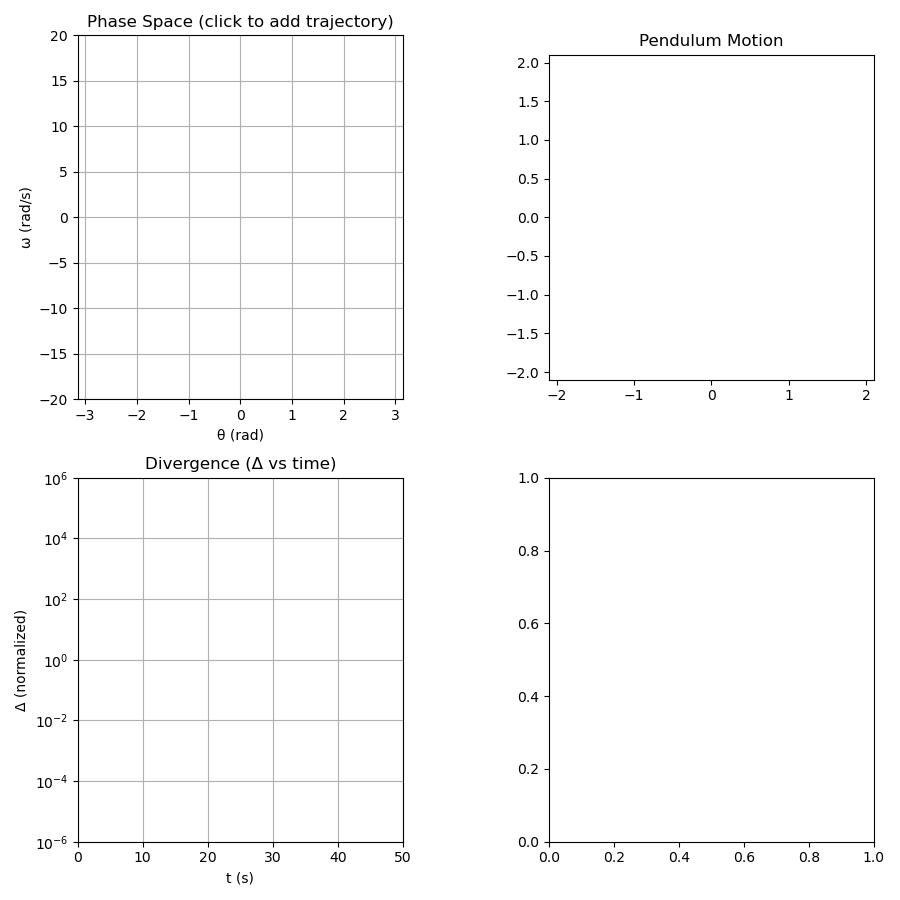

In [21]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from ipywidgets import Button, VBox, HBox, Output
from IPython.display import display

# Parameters
g = 9.81
L = 1.0
a = 1        # pivot amplitude (m)
Omega = 2    # drive freq (rad/s)

# perturbation for divergence
delta_theta = 1e-4
delta_omega = 0.0

# output parameters
dt = 0.01 # integrator timestep
tmax = 20.0
tmax_div = 50
Nout = 1000
Nsec = 100
t_out = np.linspace(0, tmax, Nout)
t_sec = np.arange(Nsec)*(2*np.pi/Omega)
t_div = np.linspace(0, tmax_div, Nout)

# ======================
# Dynamics (correct driven eqn)
# ======================
def angular_accel(theta, t):
    # correct sign: g - a * Omega^2 * cos(...) appears in numerator
    return - ((g - a * Omega**2 * np.cos(Omega * t)) / L) * np.sin(theta)

# ======================
# Symplectic leapfrog integrator
# ======================
def integrate_leapfrog(theta0, omega0, t_out, dt=0.001):
    """
    Symplectic leapfrog integrator for driven pendulum.

    Parameters
    ----------
    theta0, omega0 : float
        Initial conditions.
    t_out : array_like
        Array of times at which to return results (need not be uniform).
    dt : float
        Internal integration timestep.

    Returns
    -------
    t_out : ndarray
        Output times (same as input, sorted).
    theta_out, omega_out : ndarray
        Arrays of theta and omega at each output time.
    """
    t_out = np.array(t_out)
    t_out.sort()
    t_end = t_out[-1]

    # Preallocate output arrays
    theta_out = np.zeros_like(t_out)
    omega_out = np.zeros_like(t_out)

    # Initial conditions
    theta = float(theta0)
    omega = float(omega0) + 0.5 * dt * angular_accel(theta, 0.0)  # half-step

    # Integration loop
    t = 0.0
    next_index = 0
    n_out = len(t_out)

    for step in range(int(t_end / dt) + 2):
        # Output if we've reached or passed a requested output time
        while next_index < n_out and t >= t_out[next_index]:
            theta_out[next_index] = theta
            omega_out[next_index] = omega - 0.5 * dt * angular_accel(theta, t)  # back to integer step
            next_index += 1
            if next_index == n_out:
                break
        if next_index == n_out:
            break

        # Standard leapfrog update
        theta += dt * omega
        omega += dt * angular_accel(theta, t + 0.5 * dt)
        t += dt

        # wrap angle to [-pi, pi]
        if theta > np.pi:
            theta -= 2 * np.pi
        elif theta < -np.pi:
            theta += 2 * np.pi

    return t_out, theta_out, omega_out

# ======================
# Divergence (chaos) diagnostic (normalized)
# ======================
def compute_divergence(theta0, omega0, dtheta, domega):
    t1, th1, om1 = integrate_leapfrog(theta0, omega0, t_div, dt)
    t2, th2, om2 = integrate_leapfrog(theta0 + dtheta, omega0 + domega, t_div, dt)
    # same time grid by construction
    delta = np.sqrt((th2 - th1)**2 + (om2 - om1)**2)
    # avoid division by zero
    norm0 = delta[0] if delta[0] > 0 else 1e-16
    delta = delta / norm0
    return t1, delta

# ======================
# Figure / axes setup
# ======================
fig, ((ax_phase, ax_pend), (ax_div, ax_blank)) = plt.subplots(2, 2, figsize=(9, 9))

# pendulum picture
ax_pend.set_title("Pendulum Motion")
ax_pend.set_xlim(-L - a - 0.1, L + a + 0.1)
ax_pend.set_ylim(-L - a - 0.1, L + a + 0.1)
ax_pend.set_aspect('equal')

# phase space
ax_phase.set_title("Phase Space (click to add trajectory)")
ax_phase.set_xlabel("θ (rad)")
ax_phase.set_ylabel("ω (rad/s)")
ax_phase.set_xlim(-np.pi, np.pi)
ax_phase.set_ylim(-20, 20)
ax_phase.grid(True)

# divergence
ax_div.set_title("Divergence (Δ vs time)")
ax_div.set_xlabel("t (s)")
ax_div.set_ylabel("Δ (normalized)")
ax_div.set_yscale("log")
ax_div.set_xlim(0, t_div[-1])
ax_div.set_ylim(1e-6, 1e6)
ax_div.grid(True)
ax_div.set_yscale('log')

plt.tight_layout()
plt.subplots_adjust(wspace=0.45)

# ======================
# State containers
# ======================
trajectories = []   # static phase-space traces
div_lines = []      # divergence plot lines
animations = []     # keep references to animations if needed

# output widget
out = Output()
display(VBox([out]))

# current running animation and its artists (we'll stop/remove before starting new)
current_animation = {"ani": None, "pend_line": None, "trace_line": None}

# ======================
# Utility: stop & remove current animation and its artists
# ======================
def stop_current_animation():
    ani = current_animation.get("ani")
    if ani is not None:
        # stop event source
        try:
            ani.event_source.stop()
        except Exception:
            pass
    # remove artists from axes so they won't be visible/updated
    for key in ("pend_line", "trace_line"):
        art = current_animation.get(key)
        if art is not None:
            try:
                art.remove()
            except Exception:
                pass
    # clear stored refs
    current_animation["ani"] = None
    current_animation["pend_line"] = None
    current_animation["trace_line"] = None
    # redraw canvas
    try:
        fig.canvas.draw_idle()
    except Exception:
        pass

# ======================
# animate_pendulum (creates a new FuncAnimation but uses its own artists)
# ======================
def animate_pendulum(t_vals, theta_vals, omega_vals, color='C1'):
    # stop & remove previous animation + artists first
    stop_current_animation()

    # create local artists for this animation (so multiple animations don't share artists)
    pend_line, = ax_pend.plot([], [], 'o-', lw=2, color=color)
    trace_line, = ax_phase.plot([], [], lw=1.5, color=color)

    # store them in current_animation so we can remove later
    current_animation["pend_line"] = pend_line
    current_animation["trace_line"] = trace_line

    # update function for this animation
    def update(frame_index):
        i = int(frame_index)
        if i < 0 or i >= len(t_vals):
            return pend_line, trace_line

        t_now = float(t_vals[i])
        theta = float(theta_vals[i])
        omega = float(omega_vals[i])

        y_pivot = a * np.cos(Omega * t_now)
        x = L * np.sin(theta)
        y = y_pivot - L * np.cos(theta)

        pend_line.set_data([0.0, x], [y_pivot, y])
        #trace_line.set_data(theta_vals[:i], omega_vals[:i])
        return pend_line, trace_line

    # create animation for exactly len(t_vals) frames
    ani = FuncAnimation(fig, update, frames=range(len(t_vals)),
                        interval=dt*1000, blit=True, repeat=False)

    # keep reference & return
    current_animation["ani"] = ani
    animations.append(ani)
    return ani

# ======================
# Click handler
# ======================
def on_click(event):
    if event.inaxes != ax_phase:
        return

    theta0, omega0 = float(event.xdata), float(event.ydata)

    # integrate using leapfrog
    t_vals, theta_vals, omega_vals = integrate_leapfrog(theta0, omega0, t_out, dt)
    sec_t_vals, sec_theta_vals, sec_omega_vals = integrate_leapfrog(theta0, omega0, t_sec, dt)

    line = ax_phase.plot(sec_theta_vals, sec_omega_vals, '.', alpha=0.8)[0]
    trajectories.append(line)
    fig.canvas.draw_idle()

    # divergence
    t_div, delta = compute_divergence(theta0, omega0, delta_theta, delta_omega)
    div_line = ax_div.plot(t_div, delta, lw=1.2)[0]
    div_lines.append(div_line)

    # start the animation for this trajectory (uses leapfrog arrays)
    animate_pendulum(t_vals, theta_vals, omega_vals, color=None)

    with out:
        print(f"Added trajectory θ0={theta0:.3f}, ω0={omega0:.3f}, max Δ≈{np.max(delta):.3e}")

# connect click
cid = fig.canvas.mpl_connect('button_press_event', on_click)

# ======================
# Clear button (stop + remove traces & divergence)
# ======================
clear_btn = Button(description="Clear", button_style="danger")
def clear_all(b=None):
    stop_current_animation()
    # remove static trajectories and div lines
    for ln in trajectories + div_lines:
        try:
            ln.remove()
        except Exception:
            pass
    trajectories.clear()
    div_lines.clear()
    fig.canvas.draw_idle()
    with out:
        out.clear_output()
        print("Cleared trajectories and divergence plots.")
clear_btn.on_click(clear_all)

# display clear button
display(HBox([clear_btn]))

# ======================
# Done — the animations will be created by animate_pendulum (leapfrog data)
# ======================
plt.show()
